**Mila Marsot**
# HW2 · Part 1: Data cleaning

The `ohlc_hw` table contains daily prices for several stocks, but the data is dirty. In this notebook I find the problems, repair them, and save a clean table called `ohlc_hw_cleaned`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from pathlib import Path
from IPython.display import display
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

key = ['ticker', 'date']
price_cols = ['open', 'high', 'low', 'close']

## 1.1 Loading and inspecting the data

I open the database in read-only mode and load two tables:

- `ohlc_hw`: the dirty data to clean;
- `ohlc`: a reference table, used only to know which trading days to expect and to repair adjusted prices.

The database calls the date column `ts`. I rename it `date` here and rename it back when I save.

In [2]:
database = Path('data/data.db')
if not database.is_file():
    raise FileNotFoundError(f'Download data.db from bCourses and place it at {database}')
conn = sqlite3.connect(database.resolve().as_uri() + '?mode=ro', uri=True)
display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn))

hw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn, parse_dates=['ts']).rename(columns={'ts': 'date'})
ohlc = pd.read_sql_query('SELECT * FROM ohlc', conn, parse_dates=['ts']).rename(columns={'ts': 'date'})
conn.close()

,name
0,market_caps
1,ohlc
2,ohlc_hw
3,ohlc_hw_cleaned
4,ohlc_hw_quality_report
5,ohlc_hw_quarantine
6,ohlc_hw_ticker_audit


`.info()` shows the type of each column and how many values are not missing. `.describe()` shows the minimum and maximum of each column, which helps spot impossible values.

In [3]:
hw.info()
display(hw.describe())
print('Date range:', hw['date'].min().date(), '->', hw['date'].max().date())
print('Raw ticker labels:', hw['ticker'].nunique())
print('Example labels:', hw['ticker'].unique()[:3])
display(hw.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   date       397711 non-null  datetime64[ns]
 1   open       397711 non-null  float64       
 2   high       397711 non-null  float64       
 3   low        397711 non-null  float64       
 4   close      397711 non-null  float64       
 5   adj_close  377856 non-null  float64       
 6   volume     397711 non-null  int64         
 7   ticker     397711 non-null  object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 24.3+ MB


,date,open,high,low,close,adj_close,volume
count,397711,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,1998-04-17 21:18:45.292485888,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
min,1962-01-02 00:00:00,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,1985-05-28 00:00:00,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,2000-01-06 00:00:00,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,2012-08-21 00:00:00,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,2024-12-06 00:00:00,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09
std,NaN,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08


Date range: 1962-01-02 -> 2024-12-06
Raw ticker labels: 150
Example labels: ['CAT' 'CVX' 'HD']


date             0
open             0
high             0
low              0
close            0
adj_close    19855
volume           0
ticker           0
dtype: int64

Each row is one stock on one day:

| Column | Meaning |
|---|---|
| `open`, `high`, `low`, `close` | First, highest, lowest and last price of the day |
| `adj_close` | Close adjusted for dividends, used to measure performance |
| `volume` | Number of shares traded |

On a valid day, the open and the close are between the low and the high.

**What I notice:**

- there are 150 ticker labels, many of them written in HTML (`<span>TRV</span>`);
- only `adj_close` has missing values;
- the minimum `open` is 0, which is impossible for a stock price;
- the maximum `adj_close` is above 10,000 while the maximum `close` is about 605.

## 1.2 Finding the problems

### Ticker names

The same stock is written in several ways, for example `AAPL` and `<span>AAPL</span>`. I remove the HTML tags and spaces and use capital letters, so each stock has one name. `ticker_audit` keeps the link between the old and the new names.

In [4]:
clean = hw.copy()
clean['ticker'] = (clean['ticker'].astype('string')
                   .str.replace(r'<[^>]+>', '', regex=True)
                   .str.strip().str.upper())
ticker_audit = (pd.DataFrame({'raw_ticker': hw['ticker'], 'ticker': clean['ticker'].astype(str)})
                .value_counts().rename('rows').reset_index())
print('Raw labels:', hw['ticker'].nunique(), '| Cleaned tickers:', clean['ticker'].nunique())
print('Tickers:', sorted(clean['ticker'].unique()))
display(ticker_audit.loc[ticker_audit['ticker'] == 'AAPL'])

Raw labels: 150 | Cleaned tickers: 30
Tickers: ['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,raw_ticker,ticker,rows
18,AAPL,AAPL,10747
98,"<a target=""_blank""><span style=""color: red"">AA...",AAPL,318
104,"<a target=""_blank""><span style=""color: blue"">A...",AAPL,307
105,"<a target=""_blank""><span style=""font-weight: b...",AAPL,306
120,"<a target=""_blank""><span style=""font-weight: b...",AAPL,264


The 150 labels correspond to 30 stocks.

### Duplicates

Some rows appear twice. If two rows are exactly the same, I can remove one. If two rows had the same stock and day but different prices, I could not know which one is right: the `assert` checks that this never happens.

In [5]:
exact_duplicates = clean.loc[clean.duplicated()]
display(clean.loc[clean.duplicated(key, keep=False)].sort_values(key).head(4))
clean = clean.drop_duplicates().sort_values(key).reset_index(drop=True)
assert not clean.duplicated(key).any(), 'Conflicting records need a source-selection rule.'
print('Exact duplicates removed:', len(exact_duplicates), '| Unique observations:', len(clean))

,date,open,high,low,close,adj_close,volume,ticker
183610,1981-01-02,0.15402,0.15402,0.15402,0.15402,0.11873,21660820,AAPL
218476,1981-01-02,0.15402,0.15402,0.15402,0.15402,0.11873,21660820,AAPL
94535,1981-01-05,0.15067,0.15067,0.15067,0.15067,0.11615,35728032,AAPL
343474,1981-01-05,0.15067,0.15067,0.15067,0.15067,0.11615,35728032,AAPL


Exact duplicates removed: 29460 | Unique observations: 368251


All the duplicates were exact copies.

### Missing days

`.isna()` finds empty cells, but not days that are missing from the table. To find those, I compare each stock with the list of days it should have, taken from `ohlc` between the stock's first and last date. Weekdays alone would include market holidays. I first check the function on a small example where January 3 is missing.

In [6]:
def missing_sessions(frame, expected_dates):
    """Return expected dates absent from one ticker's observations."""
    observed = pd.DatetimeIndex(frame['date'].dropna().unique())
    return pd.DatetimeIndex(expected_dates).difference(observed).sort_values()

expected_sessions = pd.to_datetime(['2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05'])
calendar_delivery = pd.DataFrame({'ticker': ['DEMO_A'] * 3, 'date': expected_sessions[[0, 2, 3]]})
gap_dates = missing_sessions(calendar_delivery, expected_sessions)
print(f"DEMO_A is missing {len(gap_dates)} sessions between {expected_sessions.min().date()} and {expected_sessions.max().date()}: {gap_dates.tolist()}")
assert gap_dates.tolist() == [pd.Timestamp('2024-01-03')]

DEMO_A is missing 1 sessions between 2024-01-02 and 2024-01-05: [Timestamp('2024-01-03 00:00:00')]


The function finds the missing day. Now I check every stock.

In [7]:
expected_by_ticker = ohlc.groupby('ticker')['date']
gap_parts, gap_summary = [], []
for ticker, rows in clean.groupby('ticker'):
    start, end = rows['date'].min(), rows['date'].max()
    expected = expected_by_ticker.get_group(ticker)
    gap_dates = missing_sessions(rows, expected[expected.between(start, end)])
    gap_parts.append(pd.DataFrame({'ticker': ticker, 'issue_date': gap_dates}))
    gap_summary.append(f'Ticker {ticker} is missing {len(gap_dates)} trading days between {start.date()} and {end.date()}')

gaps = pd.concat(gap_parts, ignore_index=True)
print('\n'.join(gap_summary[:5]), '\n...')
print('Missing trading days, all tickers:', len(gaps))

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18 
...
Missing trading days, all tickers: 0


No day is missing.

### Prices, volume and returns

The function below checks every row and returns a table of problems with the columns `ticker`, `issue_type`, `issue_date`, `description` and `severity`. It looks for:

- missing, zero or negative prices;
- an open or a close outside the day's low and high;
- negative or zero volume;
- extreme daily returns: more than 3 standard deviations away from the stock's average return, using the sample standard deviation, for both gains and losses.

An extreme return is not deleted. It is only a signal to look at the row more closely.

In [8]:
def price_issue_report(frame):
    """Diagnose normalized, unique ticker/date rows; statistical flags require review."""
    data = frame.sort_values(['ticker', 'date']).copy()
    price_columns = ['open', 'high', 'low', 'close']
    valid_close = data['close'].where(np.isfinite(data['close']) & data['close'].gt(0))
    returns = valid_close.groupby(data['ticker']).pct_change(fill_method=None)
    grouped = returns.groupby(data['ticker'])
    mean, std = grouped.transform('mean'), grouped.transform('std')
    masks = {
        'missing_price': data[price_columns].isna().any(axis=1),
        'invalid_price': (~np.isfinite(data[price_columns]) | data[price_columns].le(0)).any(axis=1),
        'ohlc_bounds': (data['high'].lt(data[['open', 'close']].max(axis=1))
                        | data['low'].gt(data[['open', 'close']].min(axis=1))
                        | data['high'].lt(data['low'])),
        'invalid_volume': ~np.isfinite(data['volume']) | data['volume'].lt(0),
        'zero_volume': data['volume'].eq(0),
        'extreme_return': (returns - mean).abs().gt(3 * std) & std.gt(0),
    }
    parts = []
    for issue, mask in masks.items():
        rows = data.loc[mask, ['ticker', 'date']].rename(columns={'date': 'issue_date'})
        rows['issue_type'] = issue
        rows['description'] = 'Investigate ' + issue.replace('_', ' ')
        rows['severity'] = 'medium' if issue in ['zero_volume', 'extreme_return'] else 'high'
        parts.append(rows)
    return pd.concat(parts, ignore_index=True)[['ticker', 'issue_type', 'issue_date', 'description', 'severity']]

### Adjusted close

The ratio `adj_close / close` should be the same as in the reference table for the same stock and day. I join the two tables on ticker and date, then flag adjusted closes that are missing or that don't match. I also check that the raw prices are the same in both tables.

In [9]:
# Join each row with the same stock and day in the reference table
checked = clean.merge(ohlc, on=key, how='left', suffixes=('', '_ref'), validate='one_to_one')
assert len(checked) == len(clean)
# Raw prices must match the reference before I can use its factors
print('Rows where raw values differ from the reference:',
      {col: int((checked[col] != checked[f'{col}_ref']).sum()) for col in price_cols + ['volume']})

# Compare my factor adj_close / close with the reference factor (0.1% tolerance for rounding)
trusted_factor = checked['adj_close_ref'] / checked['close_ref']
adj_masks = {
    'missing_adj_close': checked['adj_close'].isna(),
    'adj_close_mismatch': checked['adj_close'].notna() & ~np.isclose(checked['adj_close'] / checked['close'],
                                                                     trusted_factor, rtol=1e-3),
}
# Turn each mask into rows of the quality report
adj_parts = []
for issue, mask in adj_masks.items():
    rows = checked.loc[mask, ['ticker', 'date']].rename(columns={'date': 'issue_date'})
    rows['issue_type'] = issue
    rows['description'] = 'Investigate ' + issue.replace('_', ' ')
    rows['severity'] = 'medium' if issue == 'missing_adj_close' else 'high'
    adj_parts.append(rows)
adj_issues = pd.concat(adj_parts, ignore_index=True)
print({issue: int(mask.sum()) for issue, mask in adj_masks.items()})

Rows where raw values differ from the reference: {'open': 0, 'high': 0, 'low': 0, 'close': 0, 'volume': 0}
{'missing_adj_close': 18374, 'adj_close_mismatch': 10417}


The raw prices match the reference, but about 18,000 adjusted closes are missing and 10,000 are wrong (for example 2,360 for AAPL on a day it closed at 115).

### Quality report

I gather all the problems in one table. This is the diagnosis before any repair.

| Severity | Meaning | Issues |
|---|---|---|
| high | The value is impossible or wrong | missing or invalid price, open or close outside the range, invalid volume, wrong `adj_close` |
| medium | The value is missing or unusual and needs a decision | missing `adj_close`, missing day, zero volume, extreme return |
| low | Already handled | exact duplicate (removed) |

In [10]:
quality_report = pd.concat([
    price_issue_report(clean),
    adj_issues,
    gaps.assign(issue_type='missing_session', description='Absent from supplied session calendar', severity='medium'),
    exact_duplicates[key].rename(columns={'date': 'issue_date'})
        .assign(issue_type='exact_duplicate', description='Exact duplicate record removed', severity='low'),
], ignore_index=True)[['ticker', 'issue_type', 'issue_date', 'description', 'severity']]

display(quality_report.head(10))
display(quality_report.groupby(['issue_type', 'severity']).size().rename('issues'))

,ticker,issue_type,issue_date,description,severity
0,CVX,invalid_price,1962-01-02,Investigate invalid price,high
1,JNJ,invalid_price,1962-01-02,Investigate invalid price,high
2,MCD,invalid_price,1966-07-05,Investigate invalid price,high
3,MRK,invalid_price,1962-01-02,Investigate invalid price,high
4,PG,invalid_price,1962-01-02,Investigate invalid price,high
5,CVX,ohlc_bounds,1962-01-02,Investigate ohlc bounds,high
6,JNJ,ohlc_bounds,1962-01-02,Investigate ohlc bounds,high
7,MCD,ohlc_bounds,1966-07-05,Investigate ohlc bounds,high
8,MRK,ohlc_bounds,1962-01-02,Investigate ohlc bounds,high
9,PG,ohlc_bounds,1962-01-02,Investigate ohlc bounds,high


issue_type          severity
adj_close_mismatch  high        10417
exact_duplicate     low         29460
extreme_return      medium       5056
invalid_price       high            5
missing_adj_close   medium      18374
ohlc_bounds         high            5
zero_volume         medium         75
Name: issues, dtype: int64

The main problems are the duplicates and the adjusted closes. Five rows have an `open` of 0.

### Testing with errors I add myself

Some problems from the assignment are not in this database: a missing close, a close above the high, a negative volume and a row with no prices. To show that my checks would find them, I take correct AAPL data from January 2024 and add these four errors on purpose.

In [11]:
base = clean.loc[(clean['ticker'] == 'AAPL') & clean['date'].between('2024-01-02', '2024-01-31')]
base = base.reset_index(drop=True)
test = base.copy()
test.loc[3, 'close'] = np.nan                     # missing close
test.loc[6, 'close'] = test.loc[6, 'high'] * 1.1  # close above the high
test['volume'] = test['volume'].astype(float)
test.loc[9, 'volume'] = -100                      # negative volume
test.loc[12, price_cols] = np.nan                 # row with no prices

test_report = price_issue_report(test)
display(test_report.loc[test_report['issue_type'] != 'extreme_return'])
found = set(zip(test_report['issue_date'], test_report['issue_type']))
for row, issue in [(3, 'missing_price'), (6, 'ohlc_bounds'), (9, 'invalid_volume'), (12, 'missing_price')]:
    assert (base.loc[row, 'date'], issue) in found, (row, issue)
print('The checks find every error I added.')

,ticker,issue_type,issue_date,description,severity
0,AAPL,missing_price,2024-01-05,Investigate missing price,high
1,AAPL,missing_price,2024-01-19,Investigate missing price,high
2,AAPL,invalid_price,2024-01-05,Investigate invalid price,high
3,AAPL,invalid_price,2024-01-19,Investigate invalid price,high
4,AAPL,ohlc_bounds,2024-01-10,Investigate ohlc bounds,high
5,AAPL,invalid_volume,2024-01-16,Investigate invalid volume,high


The checks find every error I added.


Every error I added is found. A missing price is also counted as invalid, which is why `invalid_price` appears too.

## 1.3 Repairing the data

| Problem | Repair |
|---|---|
| All prices missing | Remove the row |
| Bad open or close | Previous close if it is between today's low and high, otherwise the middle of the low and the high |
| Missing high or low | Previous value of the same stock |
| Missing or wrong `adj_close` | `close × factor` from the reference table |
| Bad volume | 0, marked as repaired |

I don't simply copy yesterday's close, because it could be outside today's range. Each repaired value gets a `_repaired` flag, so I always know which values are estimates. The function below applies all these rules.

In [12]:
reference = ohlc[key + ['close', 'adj_close']].rename(columns={'close': 'ref_close', 'adj_close': 'ref_adj_close'})


def clean_prices(frame, reference):
    """Repair unique, normalized rows; return (clean, removed, set_aside)."""
    clean = frame.sort_values(key).reset_index(drop=True)

    # Rows with all four prices missing are removed; a missing high or low takes the previous value
    all_prices_missing = clean[price_cols].isna().all(axis=1)
    removed = clean.loc[all_prices_missing].assign(reason='all raw prices missing')
    clean = clean.loc[~all_prices_missing].reset_index(drop=True)
    for col in ['high', 'low']:
        clean[f'{col}_repaired'] = clean[col].isna()
    clean[['high', 'low']] = clean.groupby('ticker')[['high', 'low']].ffill()

    # Bad close or open: previous close if inside today's range, otherwise the midpoint
    for col in ['close', 'open']:
        bad = (~np.isfinite(clean[col]) | (clean[col] <= 0)
               | (clean[col] < clean['low']) | (clean[col] > clean['high']))
        clean[f'{col}_repaired'] = bad
        clean.loc[bad, col] = np.nan
    previous = clean.groupby('ticker')['close'].ffill()
    within_range = previous.between(clean['low'], clean['high'])
    midpoint = (clean['high'] + clean['low']) / 2
    replacement = previous.where(within_range, midpoint)
    clean['close'] = clean['close'].fillna(replacement)
    clean['open'] = clean['open'].fillna(replacement)

    # Missing or wrong adjusted close: close x factor from the reference table
    clean = clean.merge(reference, on=key, how='left', validate='one_to_one')
    trusted_factor = clean['ref_adj_close'] / clean['ref_close']
    clean['adj_close_repaired'] = (clean['adj_close'].isna() | clean['close_repaired']
                                   | ~np.isclose(clean['adj_close'] / clean['close'], trusted_factor, rtol=1e-3))
    clean.loc[clean['adj_close_repaired'], 'adj_close'] = clean['close'] * trusted_factor
    clean = clean.drop(columns=['ref_close', 'ref_adj_close'])

    # Bad volume: 0, marked as repaired (an unknown volume does not mean no trading)
    invalid_volume = ~np.isfinite(clean['volume']) | (clean['volume'] < 0)
    clean['volume_repaired'] = invalid_volume
    clean.loc[invalid_volume, 'volume'] = 0
    clean['volume'] = clean['volume'].astype('int64')

    # Rows that still have a missing value are put aside
    unresolved = clean[price_cols + ['adj_close']].isna().any(axis=1)
    set_aside = clean.loc[unresolved].assign(reason='no earlier price or trusted factor to repair from')
    return clean.loc[~unresolved].reset_index(drop=True), removed, set_aside

I first test the repairs on the data with errors I added.

In [13]:
test_clean, test_removed, test_set_aside = clean_prices(test, reference)
repaired = test_clean['close_repaired'] | test_clean['volume_repaired']
display(test_clean.loc[repaired, key + price_cols + ['volume', 'close_repaired', 'volume_repaired']])

assert len(test_removed) == 1  # the row with no prices
assert test_clean['close'].between(test_clean['low'], test_clean['high']).all()
assert test_clean['close_repaired'].sum() == 2 and test_clean['volume_repaired'].sum() == 1
print('The errors I added are repaired.')

,ticker,date,open,high,low,close,volume,close_repaired,volume_repaired
3,AAPL,2024-01-05,181.99,182.76,180.17,181.91,62379661,True,False
6,AAPL,2024-01-10,184.35,186.40,183.92,185.14,46792908,True,False
9,AAPL,2024-01-16,182.16,184.26,180.93,183.63,0,False,True


The errors I added are repaired.


The repairs work. Now I clean the real data.

In [14]:
before_repairs = clean.copy()
clean, removed, set_aside = clean_prices(before_repairs, reference)
display(clean.filter(like='_repaired').sum().rename('repaired values').to_frame().T)
display(clean.loc[clean['open_repaired'], key + price_cols])
print('Rows removed:', len(removed), '| Rows set aside:', len(set_aside))

,high_repaired,low_repaired,close_repaired,open_repaired,adj_close_repaired,volume_repaired
repaired values,0,0,0,5,28791,0


,ticker,date,open,high,low,close
87103,CVX,1962-01-02,3.30000,3.30000,3.24000,3.30000
167733,JNJ,1962-01-02,0.22338,0.22338,0.22222,0.22338
213412,MCD,1966-07-05,0.26955,0.27366,0.26749,0.26955
243893,MRK,1962-01-02,0.39537,0.39703,0.39317,0.39537
287040,PG,1962-01-02,1.43000,1.44000,1.42000,1.43000


Rows removed: 0 | Rows set aside: 0


The five opens equal to 0 were on the first day of a stock's history. There is no previous close, so the open takes the close of the same day. All the other repairs are adjusted closes.

### Extreme returns

Most extreme returns are real market moves and should be kept. But some days look like errors: the volume is 0, the price does not move during the day, it jumps, and the next day it comes back to where it was. Since nobody traded, the price could not really move. I replace these prices with the average of the day before and the day after.

In [15]:
# Extreme daily returns, computed separately for each stock
clean['return'] = clean.groupby('ticker')['close'].pct_change(fill_method=None)
grouped = clean.groupby('ticker')['return']
extreme = (clean['return'] - grouped.transform('mean')).abs().gt(3 * grouped.transform('std'))
# A stale quote: nobody traded and the price stayed flat all day
stale_quote = clean['volume'].eq(0) & clean['high'].eq(clean['low'])
# An error: the price jumps on a stale quote and is back within 5% the next day
close_before = clean.groupby('ticker')['close'].shift(1)
close_after = clean.groupby('ticker')['close'].shift(-1)
confirmed_error = extreme & stale_quote & (close_after / close_before - 1).abs().lt(0.05)
display(clean.loc[confirmed_error, key + price_cols + ['volume']]
        .assign(close_before=close_before, close_after=close_after))

# Replace these prices with the average of the day before and the day after
interpolated_cols = price_cols + ['adj_close']
clean.loc[confirmed_error, interpolated_cols] = np.nan
clean[interpolated_cols] = clean.groupby('ticker')[interpolated_cols].transform(lambda s: s.interpolate(limit_area='inside'))
for col in interpolated_cols:
    clean[f'{col}_repaired'] |= confirmed_error

,ticker,date,open,high,low,close,volume,close_before,close_after
28586,AXP,1972-12-14,4.01,4.01,4.01,4.01,0,4.59,4.60
318332,TRV,1976-10-28,9.22,9.22,9.22,9.22,0,4.61,4.69
318873,TRV,1978-12-20,8.03,8.03,8.03,8.03,0,4.02,4.09
319538,TRV,1981-08-10,12.06,12.06,12.06,12.06,0,6.03,6.03


4 days were errors. Now I mark the extreme returns I keep, and the days with zero volume.

In [16]:
clean['return'] = clean.groupby('ticker')['close'].pct_change(fill_method=None)
grouped = clean.groupby('ticker')['return']
clean['extreme_return_flag'] = (clean['return'] - grouped.transform('mean')).abs().gt(3 * grouped.transform('std'))
clean['zero_volume_flag'] = clean['volume'].eq(0) & ~clean['volume_repaired']
print('Extreme returns kept and flagged:', clean['extreme_return_flag'].sum())
display(clean.loc[clean['return'].abs().nlargest(6).index, key + ['close', 'high', 'low', 'volume', 'return']])

zero_volume = clean.loc[clean['zero_volume_flag']]
print(f"Zero-volume days: {len(zero_volume)}, between {zero_volume['date'].min().date()} and "
      f"{zero_volume['date'].max().date()}, {zero_volume['high'].eq(zero_volume['low']).sum()} with high = low")

Extreme returns kept and flagged: 5173


,ticker,date,close,high,low,volume,return
213788,MCD,1968-01-02,0.174900,0.17490,0.17490,6755143,-0.753620
4999,AAPL,2000-09-29,0.459820,0.51786,0.45313,3128875900,-0.518695
280845,NVDA,2000-03-07,0.173570,0.18177,0.14948,1952246199,0.424106
281954,NVDA,2004-08-06,0.078584,0.08500,0.07750,5092064120,-0.352314
336480,UNH,2008-10-13,23.380000,23.52000,17.83000,17691904,0.347550
22610,AMZN,2001-11-26,0.610500,0.61100,0.49000,1013784000,0.344714


Zero-volume days: 75, between 1962-01-02 and 1982-09-24, 72 with high = low


Most of the largest returns are real events, like Apple's 52% fall on 29 September 2000. One case is uncertain: MCD on 1968-01-02 falls 75% on a flat price (high = low) and stays at the new level. It could be a split missing from the data, but nothing proves it, so I keep it with its flag. The zero-volume days are all before 1983 and their prices are valid, so I keep them with a flag.

### Final checks

These checks stop the notebook if something is still wrong: missing or negative prices, an open or close outside the low and high, a negative volume or a duplicate day.

In [17]:
assert np.isfinite(clean[price_cols + ['adj_close']]).all().all()
assert clean[price_cols + ['adj_close']].gt(0).all().all()
assert clean['close'].between(clean['low'], clean['high']).all()
assert clean['open'].between(clean['low'], clean['high']).all()
assert np.isfinite(clean['volume']).all() and clean['volume'].ge(0).all()
assert not clean.duplicated(key).any()
recheck = price_issue_report(clean)
print('Checks passed. Issues left:', recheck['issue_type'].value_counts().to_dict())

Checks passed. Issues left: {'extreme_return': 5173, 'zero_volume': 75}


All checks pass. Only the extreme returns and zero volumes are left, and I kept them on purpose.

### Before and after

In [18]:
accounting = pd.Series({
    'raw rows': len(hw),
    'exact duplicates removed': len(exact_duplicates),
    'rows with all prices missing removed': len(removed),
    'rows set aside': len(set_aside),
    'rows retained': len(clean),
})
assert accounting['raw rows'] == accounting.iloc[1:].sum()
display(accounting.rename('rows').to_frame())
summary_cols = ['open', 'close', 'adj_close', 'volume']
display(pd.concat({'before': before_repairs[summary_cols].describe().loc[['count', 'min', 'max']],
                   'after': clean[summary_cols].describe().loc[['count', 'min', 'max']]}))

,rows
raw rows,397711
exact duplicates removed,29460
rows with all prices missing removed,0
rows set aside,0
rows retained,368251


open          close      adj_close        volume
before count  368251.000000  368251.000000  349877.000000  3.682510e+05
       min         0.000000       0.005208       0.002945  0.000000e+00
       max       604.260000     605.400000   10442.510783  9.276606e+09
after  count  368251.000000  368251.000000  368251.000000  3.682510e+05
       min         0.005208       0.005208       0.002945  0.000000e+00
       max       604.260000     605.400000     605.400000  9.276606e+09

Every original row is accounted for, the minimum open is no longer 0, and `adj_close` is now complete.

The chart shows the adjusted close of the stock with the most wrong values, before (red) and after (blue) cleaning.

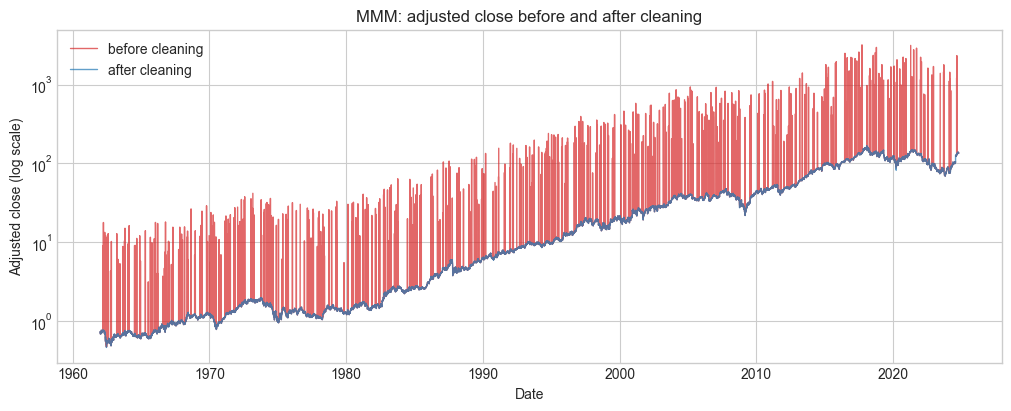

In [19]:
example = adj_issues.loc[adj_issues['issue_type'] == 'adj_close_mismatch', 'ticker'].value_counts().index[0]
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for label, frame, color in [('before cleaning', before_repairs, 'tab:red'), ('after cleaning', clean, 'tab:blue')]:
    rows = frame.loc[frame['ticker'] == example]
    ax.plot(rows['date'], rows['adj_close'], color=color, lw=1, alpha=0.7, label=label)
ax.set(title=f'{example}: adjusted close before and after cleaning', xlabel='Date',
       ylabel='Adjusted close (log scale)', yscale='log')
ax.legend()
plt.show()

### Saving

I save the clean table with its flags as `ohlc_hw_cleaned`, with dates written `YYYY-MM-DD`. I also save the quality report and the ticker list. Then I read the table back to check it was saved correctly.

In [20]:
# Final table: prices, volume and flags (saved as 0/1), dates as YYYY-MM-DD text
flag_cols = [f'{col}_repaired' for col in price_cols + ['adj_close', 'volume']] + ['zero_volume_flag', 'extreme_return_flag']
cleaned_table = clean[key + price_cols + ['adj_close', 'volume'] + flag_cols].copy()
cleaned_table[flag_cols] = cleaned_table[flag_cols].astype(int)
cleaned_table['ticker'] = cleaned_table['ticker'].astype(str)
cleaned_table['date'] = cleaned_table['date'].dt.strftime('%Y-%m-%d')
cleaned_table = cleaned_table.rename(columns={'date': 'ts'})
report_table = quality_report.assign(ticker=quality_report['ticker'].astype(str),
                                     issue_date=quality_report['issue_date'].dt.strftime('%Y-%m-%d'))

# Save the tables in my local copy of the database
write_conn = sqlite3.connect(database)
cleaned_table.to_sql('ohlc_hw_cleaned', write_conn, if_exists='replace', index=False)
report_table.to_sql('ohlc_hw_quality_report', write_conn, if_exists='replace', index=False)
ticker_audit.to_sql('ohlc_hw_ticker_audit', write_conn, if_exists='replace', index=False)
roundtrip = pd.read_sql_query('SELECT * FROM ohlc_hw_cleaned', write_conn)
raw_rows = pd.read_sql_query('SELECT COUNT(*) AS n FROM ohlc_hw', write_conn)['n'].item()
write_conn.close()

# The saved table must be identical to mine, and ohlc_hw must be unchanged
pd.testing.assert_frame_equal(roundtrip, cleaned_table)
assert raw_rows == len(hw)
print(f'ohlc_hw_cleaned: {len(roundtrip):,} rows saved and read back; ohlc_hw unchanged ({raw_rows:,} rows)')

ohlc_hw_cleaned: 368,251 rows saved and read back; ohlc_hw unchanged (397,711 rows)


In [21]:
display(cleaned_table)

,ticker,ts,open,high,low,close,adj_close,volume,open_repaired,high_repaired,low_repaired,close_repaired,adj_close_repaired,volume_repaired,zero_volume_flag,extreme_return_flag
0,AAPL,1980-12-12,0.12835,0.12835,0.12835,0.12835,0.098941,469034068,0,0,0,0,0,0,0,0
1,AAPL,1980-12-15,0.12165,0.12165,0.12165,0.12165,0.093779,175884971,0,0,0,0,0,0,0,0
2,AAPL,1980-12-16,0.11272,0.11272,0.11272,0.11272,0.086896,105728103,0,0,0,0,0,0,0,0
3,AAPL,1980-12-17,0.11551,0.11551,0.11551,0.11551,0.089046,86441684,0,0,0,0,0,0,0,0
4,AAPL,1980-12-18,0.11886,0.11886,0.11886,0.11886,0.091627,73449671,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368246,WMT,2024-10-14,80.05000,80.51000,79.76000,80.29000,80.290000,9914500,0,0,0,0,0,0,0,0
368247,WMT,2024-10-15,80.67000,81.82000,80.51000,81.65000,81.650000,13276221,0,0,0,0,0,0,0,0
368248,WMT,2024-10-16,81.53000,81.66000,80.62000,81.22000,81.220000,11123300,0,0,0,0,0,0,0,0
368249,WMT,2024-10-17,81.27000,81.50000,80.65000,80.89000,80.890000,9424705,0,0,0,0,0,0,0,0


## Summary

- **Tickers:** 150 labels cleaned into 30 stocks.
- **Duplicates:** 29,460 exact duplicates removed, no conflicting ones.
- **Missing days:** none.
- **Prices:** 5 opens equal to 0 repaired; 4 one-day errors on zero-volume days replaced by the average of their neighbours.
- **Adjusted close:** 28,791 missing or wrong values rebuilt from the reference factor.
- **Kept with a flag:** extreme returns that are real market moves, and zero-volume days.